# Paris Airbnb host revenue forecast — preliminary analysis

**Goal.** Given a Paris listing, estimate its short-term-rental revenue over the next 12 months, with and without the Paris 90-night cap.

**Data.** Inside Airbnb, Paris snapshot (detailed `listings` and `reviews` files).

**Method in one paragraph.** Inside Airbnb has no bookings, so revenue is estimated from reviews (their "San Francisco model"):

$$\text{nights}_{12m} = \min\left(\frac{\text{reviews}_{12m}}{r}\times\max(L,\ \text{min\_nights}),\ 0.70\times 365\right),\qquad \text{revenue}_{12m} = \text{nights}_{12m}\times\text{nightly price}$$

We set a cutoff 12 months before the snapshot, build features from information **before** the cutoff, and predict the estimated revenue of the 12 months **after** it. Two scenarios: **B** = no cap, **A** = nights capped at 90 (primary residences in Paris, since 1 Jan 2025).

> The target is itself an estimate. Every number below depends on the review rate `r` and the average stay `L`; see the sensitivity section.

## 1. Parameters

In [1]:
from pathlib import Path

DATA_DIR = Path(".")          # folder containing listings.csv / reviews.csv (or the slim/ copies)
OUT_DIR = Path("results_nb")  # where tables and figures are saved

REVIEW_RATE = 0.50   # share of stays that leave a review (Inside Airbnb default)
STAY_NIGHTS = 5.2    # average nights per stay. Paris value implied by Inside Airbnb's own
                     # estimated_occupancy_l365d (10.4 nights per review at r = 50%); generic default is 3
OCC_CAP = 0.70       # occupancy cap (share of the year)
LEGAL_CAP = 90       # Paris primary residence: max nights per year
CENTER = (48.8530, 2.3499)   # Notre-Dame, city-centre reference point
SEED = 42

## 2. Imports and helper functions

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
BLUE, GREY = "#4C6EF5", "#ADB5BD"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def parse_price(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")


def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def nights_from_reviews(n_reviews, min_nights, review_rate=REVIEW_RATE, stay=STAY_NIGHTS):
    # Estimated occupied nights in a 12-month window.
    stay_len = np.maximum(stay, min_nights.fillna(stay).clip(upper=30))
    return np.minimum(n_reviews / review_rate * stay_len, OCC_CAP * 365)

## 3. Load the data

The notebook looks for the slim copies first (`slim/listings_slim.csv.gz`, `slim/reviews_slim.csv.gz`), then the full CSVs. Only `listing_id` and `date` are read from the reviews file, so the 800 MB file loads fine.

In [3]:
def first_existing(*names):
    for n in names:
        if (DATA_DIR / n).exists():
            return DATA_DIR / n
    raise FileNotFoundError(f"none of {names} found in {DATA_DIR.resolve()}")

listings_path = first_existing("slim/listings_slim.csv.gz", "listings.csv.gz", "listings.csv")
reviews_path = first_existing("slim/reviews_slim.csv.gz", "reviews.csv.gz", "reviews.csv")

L = pd.read_csv(listings_path, low_memory=False)
R = pd.read_csv(reviews_path, usecols=["listing_id", "date"], parse_dates=["date"])

snapshot = pd.to_datetime(L["last_scraped"]).max()
cutoff = snapshot - pd.DateOffset(months=12)
print(f"listings: {L.shape[0]:,} rows x {L.shape[1]} columns")
print(f"reviews : {R.shape[0]:,} rows, {R['date'].min().date()} to {R['date'].max().date()}")
print(f"snapshot: {snapshot.date()}   cutoff: {cutoff.date()}")

listings: 77,149 rows x 76 columns
reviews : 2,503,875 rows, 2010-01-26 to 2026-09-22
snapshot: 2026-09-24   cutoff: 2025-09-24


## 4. Sample selection and feature building

Filters: entire homes only, a listed price between 20 and 1,000 EUR, minimum stay under 30 nights (30+ is a mid-term / mobility lease, not a tourist rental), and at least one review before the cutoff. New listings without history are the cold-start case, to be handled separately.

In [4]:
df = L.copy()
df["price_eur"] = parse_price(df["price"])
funnel = {"all listings": len(df)}
df = df[df["room_type"] == "Entire home/apt"];          funnel["entire home"] = len(df)
df = df[df["price_eur"].notna()];                       funnel["with a price"] = len(df)
df = df[df["price_eur"].between(20, 1000)];             funnel["price 20-1,000 EUR"] = len(df)
df = df[df["minimum_nights"].fillna(1) < 30];           funnel["minimum stay < 30 nights"] = len(df)

pre = R[R["date"] < cutoff]
post = R[(R["date"] >= cutoff) & (R["date"] < snapshot)]
last12_pre = pre[pre["date"] >= cutoff - pd.DateOffset(months=12)]

agg = pd.DataFrame({
    "rev_total_pre": pre.groupby("listing_id").size(),               # all reviews before cutoff
    "rev_12m_pre": last12_pre.groupby("listing_id").size(),          # reviews in the 12 months before cutoff
    "first_review_pre": pre.groupby("listing_id")["date"].min(),
    "rev_12m_post": post.groupby("listing_id").size(),               # reviews in the target year
})
df = df.merge(agg, left_on="id", right_index=True, how="left")
df = df[df["rev_total_pre"].fillna(0) > 0].copy();      funnel["reviewed before cutoff"] = len(df)
df[["rev_12m_pre", "rev_12m_post"]] = df[["rev_12m_pre", "rev_12m_post"]].fillna(0)
df["months_active_pre"] = (cutoff - df["first_review_pre"]).dt.days / 30.44

# estimated nights and revenue, before (pre) and after (post) the cutoff
df["nights_pre"] = nights_from_reviews(df["rev_12m_pre"], df["minimum_nights"])
df["nights_post"] = nights_from_reviews(df["rev_12m_post"], df["minimum_nights"])
for when in ("pre", "post"):
    df[f"rev_eur_{when}_B"] = df[f"nights_{when}"] * df["price_eur"]
    df[f"rev_eur_{when}_A"] = np.minimum(df[f"nights_{when}"], LEGAL_CAP) * df["price_eur"]

# listing features
df["dist_center_km"] = haversine_km(df["latitude"], df["longitude"], *CENTER)
df["bathrooms_n"] = pd.to_numeric(df["bathrooms_text"].astype(str).str.extract(r"([\d.]+)")[0], errors="coerce")
df["superhost"] = (df["host_is_superhost"] == "t").astype(int)
df["instant"] = (df["instant_bookable"] == "t").astype(int)

pd.Series(funnel, name="listings").to_frame()

,listings
all listings,77149
entire home,68333
with a price,38131
"price 20-1,000 EUR",36715
minimum stay < 30 nights,31047
reviewed before cutoff,21100


### Sanity check against Inside Airbnb's own occupancy field

The listings file ships with `estimated_occupancy_l365d`. If our formula is right, our estimate for the same 12 months should match it.

In [5]:
check = pd.Series({
    "Spearman correlation": df["nights_post"].corr(df["estimated_occupancy_l365d"], method="spearman"),
    "median nights (ours)": df["nights_post"].median(),
    "median nights (Inside Airbnb)": df["estimated_occupancy_l365d"].median(),
}, name="value").to_frame()
check

,value
Spearman correlation,1.00
median nights (ours),93.60
median nights (Inside Airbnb),94.00


## 5. What the estimated revenue looks like

In [6]:
overall = pd.Series({
    "listings in sample": len(df),
    "median nightly price (EUR)": df["price_eur"].median(),
    "median estimated nights": df["nights_post"].median(),
    "share with zero reviews in target year": (df["rev_12m_post"] == 0).mean(),
    "share above 90 nights": (df["nights_post"] > LEGAL_CAP).mean(),
    "revenue B: P25 (EUR)": df["rev_eur_post_B"].quantile(.25),
    "revenue B: median (EUR)": df["rev_eur_post_B"].median(),
    "revenue B: P75 (EUR)": df["rev_eur_post_B"].quantile(.75),
    "revenue A (90-night cap): median (EUR)": df["rev_eur_post_A"].median(),
}, name="value").to_frame()
overall

,value
listings in sample,"21,100.00"
median nightly price (EUR),241.67
median estimated nights,93.60
share with zero reviews in target year,0.16
share above 90 nights,0.51
revenue B: P25 (EUR),"5,158.40"
revenue B: median (EUR),"21,372.00"
revenue B: P75 (EUR),"46,622.54"
revenue A (90-night cap): median (EUR),"14,670.00"


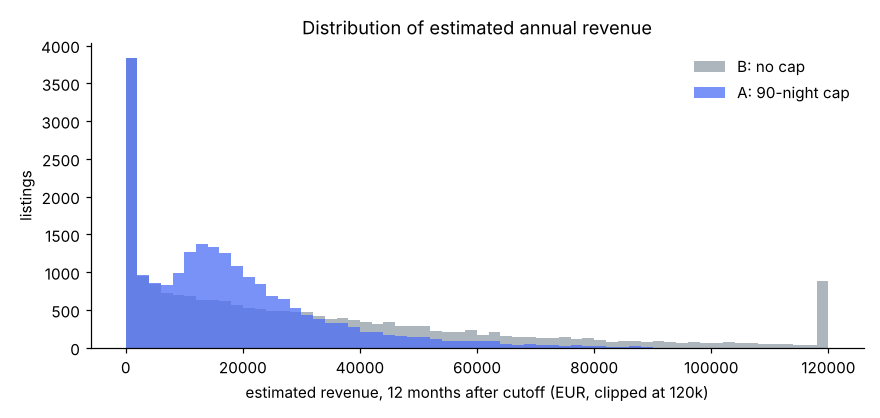

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, 120_000, 61)
ax.hist(df["rev_eur_post_B"].clip(upper=120_000), bins=bins, color=GREY, label="B: no cap")
ax.hist(df["rev_eur_post_A"].clip(upper=120_000), bins=bins, color=BLUE, alpha=.75, label="A: 90-night cap")
ax.set_xlabel("estimated revenue, 12 months after cutoff (EUR, clipped at 120k)")
ax.set_ylabel("listings"); ax.legend(frameon=False)
ax.set_title("Distribution of estimated annual revenue")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "revenue_distribution.png", dpi=150); plt.show()

## 6. Revenue model

Gradient boosting with quantile loss gives P10 / P50 / P90 instead of a single number. The benchmark is the naive forecast "next year = last year". `number_of_reviews` is excluded because it is measured at the snapshot and would leak the target.

In [8]:
NUM = ["accommodates", "bedrooms", "beds", "bathrooms_n", "dist_center_km", "minimum_nights",
       "review_scores_rating", "review_scores_location", "superhost", "instant",
       "calculated_host_listings_count", "price_eur", "rev_total_pre", "rev_12m_pre", "months_active_pre"]

X = df[NUM].apply(pd.to_numeric, errors="coerce").copy()
X["neighbourhood_cleansed"] = df["neighbourhood_cleansed"].astype("category")
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=SEED)
print(f"train: {len(idx_tr):,} listings   test: {len(idx_te):,} listings   features: {X.shape[1]}")


def fit_quantiles(y):
    models, preds = {}, {}
    for q in (0.1, 0.5, 0.9):
        m = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=400, learning_rate=0.05,
                                          categorical_features="from_dtype", random_state=SEED)
        m.fit(X.loc[idx_tr], y.loc[idx_tr])
        models[q], preds[q] = m, np.expm1(m.predict(X.loc[idx_te]))
    return models, preds


def score(pred, actual):
    return {"MAE (EUR)": np.mean(np.abs(pred - actual)),
            "median abs. error (EUR)": np.median(np.abs(pred - actual)),
            "Spearman": pd.Series(pred).corr(pd.Series(actual), method="spearman")}

train: 16,880 listings   test: 4,220 listings   features: 16


In [9]:
rows, fitted = {}, {}
for scen, label in (("B", "B: no cap"), ("A", "A: 90-night cap")):
    y = np.log1p(df[f"rev_eur_post_{scen}"])
    models, p = fit_quantiles(y)
    actual = df.loc[idx_te, f"rev_eur_post_{scen}"].values
    naive = df.loc[idx_te, f"rev_eur_pre_{scen}"].values
    fitted[scen] = (models, p, actual)
    rows[(label, "model (P50)")] = {**score(p[0.5], actual),
                                    "P10-P90 coverage": np.mean((actual >= p[0.1]) & (actual <= p[0.9]))}
    rows[(label, "naive: last year")] = score(naive, actual)

# Scenario A, alternative: take the uncapped forecast and apply the legal cap afterwards
cap_eur = LEGAL_CAP * df.loc[idx_te, "price_eur"].values
rows[("A: 90-night cap", "model B, then capped")] = score(np.minimum(fitted["B"][1][0.5], cap_eur), fitted["A"][2])

metrics = pd.DataFrame(rows).T
metrics

MAE (EUR)  median abs. error (EUR)  \
B: no cap       model (P50)           10,319.40                 5,380.05   
                naive: last year      12,877.50                 5,809.34   
A: 90-night cap model (P50)            5,788.83                 1,066.44   
                naive: last year       4,462.60                     0.00   
                model B, then capped   3,519.39                     2.67   

                                      Spearman  P10-P90 coverage  
B: no cap       model (P50)               0.86              0.85  
                naive: last year          0.78               NaN  
A: 90-night cap model (P50)               0.85              0.83  
                naive: last year          0.79               NaN  
                model B, then capped      0.85               NaN

**Reading the table.** In scenario B the model should beat the naive baseline on MAE and on ranking (Spearman). Scenario A is harder for a direct model because about half of the listings sit exactly at the cap; compare the three A rows to see which approach works best there.

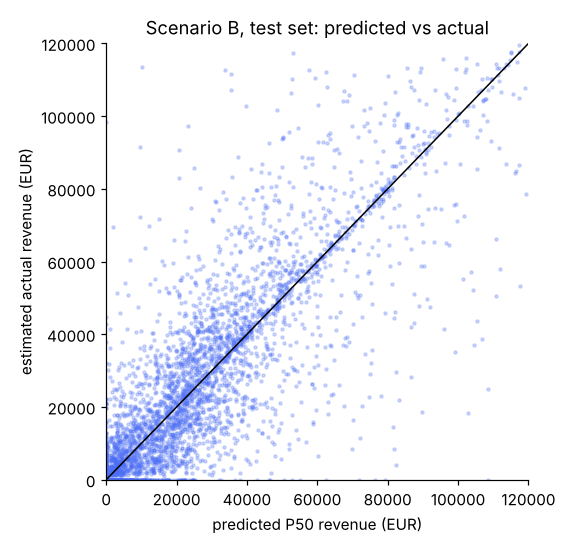

In [10]:
models_B, p_B, actual_B = fitted["B"]
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(p_B[0.5], actual_B, s=4, alpha=.25, color=BLUE)
lim = 120_000
ax.plot([0, lim], [0, lim], color="black", lw=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("predicted P50 revenue (EUR)"); ax.set_ylabel("estimated actual revenue (EUR)")
ax.set_title("Scenario B, test set: predicted vs actual")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "pred_vs_actual.png", dpi=150); plt.show()

### What drives the forecast

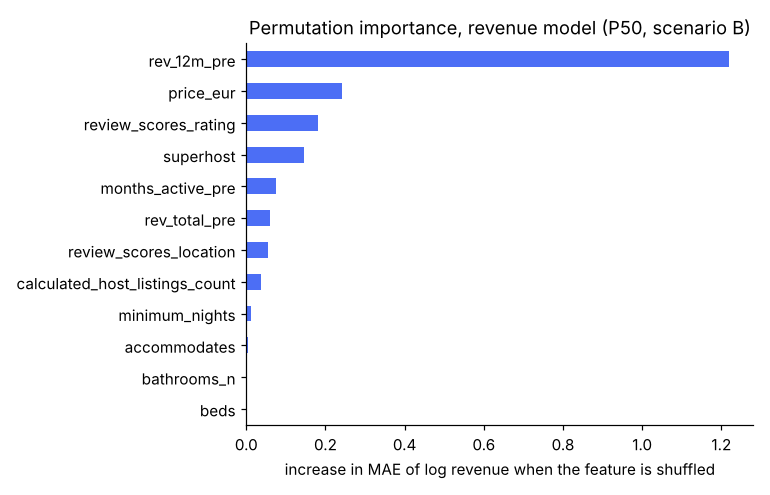

In [11]:
pi = permutation_importance(models_B[0.5], X.loc[idx_te], np.log1p(df.loc[idx_te, "rev_eur_post_B"]),
                            n_repeats=5, random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
ax = imp.tail(12).plot.barh(figsize=(7, 4.5), color=BLUE)
ax.set_title("Permutation importance, revenue model (P50, scenario B)")
ax.set_xlabel("increase in MAE of log revenue when the feature is shuffled")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_importance.png", dpi=150); plt.show()

## 7. Price model (no review history)

This is the building block for cold-start listings: predict a reasonable nightly price from the listing's attributes and location only.

In [12]:
Xp = X.drop(columns=["price_eur", "rev_total_pre", "rev_12m_pre", "months_active_pre"])
yp = np.log(df["price_eur"])
mp = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, categorical_features="from_dtype",
                                   random_state=SEED).fit(Xp.loc[idx_tr], yp.loc[idx_tr])
pred_price = np.exp(mp.predict(Xp.loc[idx_te]))
true_price = df.loc[idx_te, "price_eur"].values
r2 = 1 - np.sum((np.log(true_price) - np.log(pred_price)) ** 2) / np.sum((np.log(true_price) - np.log(true_price).mean()) ** 2)
price_metrics = pd.Series({"MAE (EUR)": np.mean(np.abs(pred_price - true_price)),
                           "R2 on log price": r2,
                           "median price (EUR)": np.median(true_price)}, name="value").to_frame()
price_metrics

,value
MAE (EUR),72.93
R2 on log price,0.64
median price (EUR),240.97


## 8. By arrondissement

In [13]:
by = df.groupby("neighbourhood_cleansed").agg(
    listings=("id", "size"),
    median_price_eur=("price_eur", "median"),
    median_nights=("nights_post", "median"),
    median_revenue_B_eur=("rev_eur_post_B", "median"),
    median_revenue_A_eur=("rev_eur_post_A", "median"),
    share_over_90_nights=("nights_post", lambda s: (s > LEGAL_CAP).mean()),
).sort_values("median_revenue_B_eur", ascending=False)
by.to_csv(OUT_DIR / "by_arrondissement.csv")
by

,listings,median_price_eur,median_nights,median_revenue_B_eur,median_revenue_A_eur,share_over_90_nights
neighbourhood_cleansed,,,,,,
Louvre,648,361.27,114.40,"43,331.60","24,733.32",0.61
Bourse,1110,319.50,135.20,"40,626.61","22,447.30",0.62
Élysée,716,373.05,114.40,"39,519.65","23,673.36",0.59
Hôtel-de-Ville,767,330.00,114.40,"34,586.55","21,805.16",0.58
Temple,1335,311.75,104.00,"33,037.68","20,412.00",0.56
Palais-Bourbon,606,346.84,93.60,"32,026.80","20,313.50",0.50
Luxembourg,646,333.50,93.60,"31,813.03","21,773.18",0.54
Panthéon,733,289.00,104.00,"29,764.80","19,305.00",0.55
Opéra,1043,277.33,93.60,"24,584.98","16,020.00",0.52


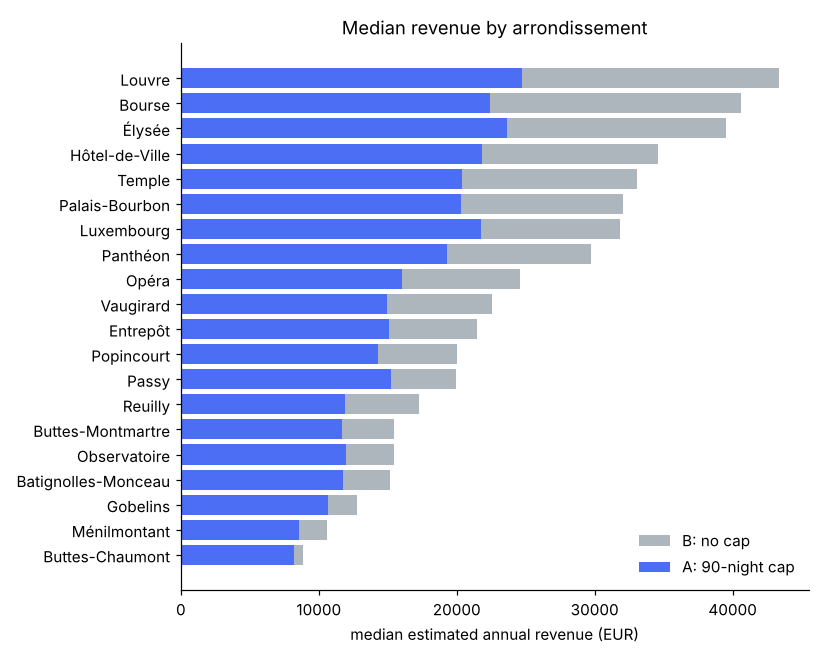

In [14]:
b = by.sort_values("median_revenue_B_eur")
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(b.index, b["median_revenue_B_eur"], color=GREY, label="B: no cap")
ax.barh(b.index, b["median_revenue_A_eur"], color=BLUE, label="A: 90-night cap")
ax.set_xlabel("median estimated annual revenue (EUR)")
ax.set_title("Median revenue by arrondissement"); ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "revenue_by_arrondissement.png", dpi=150); plt.show()

## 9. Sensitivity to the two key assumptions

Review rate `r` (30% / 50% / 72%, the range cited by Inside Airbnb) and average stay `L` (5.2 nights for Paris vs the generic default of 3).

In [15]:
sens = []
for stay in (5.2, 3.0):
    for r in (0.30, 0.50, 0.72):
        n = nights_from_reviews(df["rev_12m_post"], df["minimum_nights"], review_rate=r, stay=stay)
        sens.append({"avg stay (nights)": stay, "review rate": r,
                     "median nights": np.median(n),
                     "median revenue B (EUR)": np.median(n * df["price_eur"]),
                     "median revenue A (EUR)": np.median(np.minimum(n, LEGAL_CAP) * df["price_eur"]),
                     "share above 90 nights": (n > LEGAL_CAP).mean()})
sens = pd.DataFrame(sens).set_index(["avg stay (nights)", "review rate"])
sens.to_csv(OUT_DIR / "sensitivity.csv")
sens

median nights  median revenue B (EUR)  \
avg stay (nights) review rate                                          
5.20              0.30                156.00               32,448.25   
                  0.50                 93.60               21,372.00   
                  0.72                 65.00               14,936.28   
3.00              0.30                 90.00               22,000.00   
                  0.50                 54.00               13,310.61   
                  0.72                 37.50                9,243.75   

                               median revenue A (EUR)  share above 90 nights  
avg stay (nights) review rate                                                 
5.20              0.30                      16,560.00                   0.62  
                  0.50                      14,670.00                   0.51  
                  0.72                      12,600.00                   0.38  
3.00              0.30                      14,850.00                   0.50  
                  0.50                      11,880.00                   0.34  
                  0.72                       9,045.83                   0.24

## 10. Seasonality

Reviews per month as a proxy for stays. The last month of the series is incomplete (the snapshot is taken mid-month, and reviews lag stays), so it is dropped from the plot.

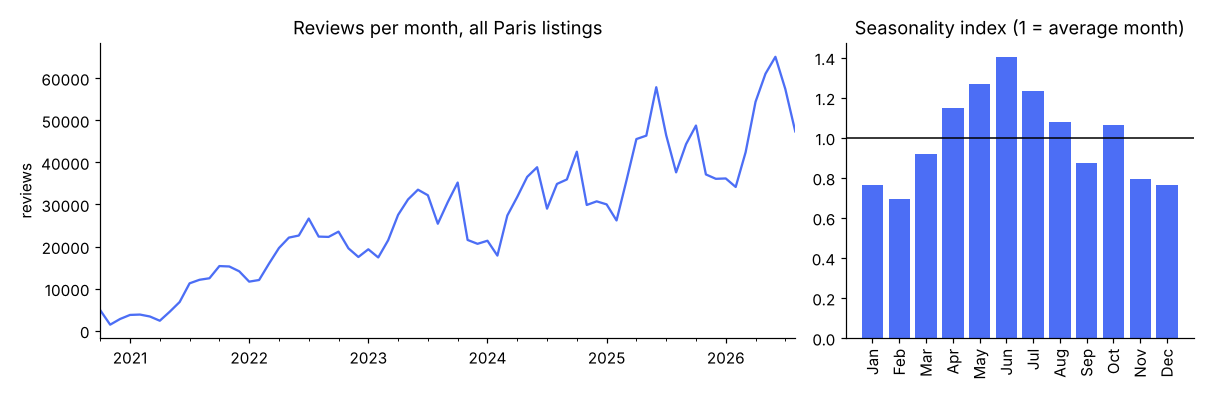

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,0.76,0.69,0.92,1.15,1.27,1.40,1.23,1.08,0.88,1.06,0.79,0.77


In [16]:
monthly = R.set_index("date").resample("MS").size()
monthly = monthly[(monthly.index >= snapshot - pd.DateOffset(years=6)) & (monthly.index < snapshot.to_period("M").to_timestamp())]
recent = R[(R["date"] >= snapshot - pd.DateOffset(years=5)) & (R["date"] < snapshot.to_period("M").to_timestamp())]
season = recent.groupby(recent["date"].dt.month).size()
season = season / season.mean()
season.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season.rename("index").to_csv(OUT_DIR / "seasonality_index.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
monthly.plot(ax=axes[0], color=BLUE)
axes[0].set_title("Reviews per month, all Paris listings"); axes[0].set_xlabel(""); axes[0].set_ylabel("reviews")
axes[1].bar(season.index, season.values, color=BLUE)
axes[1].axhline(1, color="black", lw=1)
axes[1].set_title("Seasonality index (1 = average month)")
axes[1].tick_params(axis="x", labelrotation=90)
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / "seasonality.png", dpi=150); plt.show()
season.round(2).to_frame().T

## 11. Save the summary

In [17]:
summary = {
    "snapshot": str(snapshot.date()), "cutoff": str(cutoff.date()),
    "assumptions": {"review_rate": REVIEW_RATE, "stay_nights": STAY_NIGHTS, "occupancy_cap": OCC_CAP, "legal_cap": LEGAL_CAP},
    "funnel": {k: int(v) for k, v in funnel.items()},
    "overall": {k: float(v) for k, v in overall["value"].items()},
    "revenue_models": {f"{a} | {b}": {k: (None if pd.isna(v) else float(v)) for k, v in row.items()}
                       for (a, b), row in metrics.iterrows()},
    "price_model": {k: float(v) for k, v in price_metrics["value"].items()},
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print("saved to", OUT_DIR.resolve())
print(sorted(p.name for p in OUT_DIR.iterdir()))

['by_arrondissement.csv', 'feature_importance.png', 'pred_vs_actual.png', 'revenue_by_arrondissement.png', 'revenue_distribution.png', 'seasonality.png', 'seasonality_index.csv', 'sensitivity.csv', 'summary.json']


## 12. Limits and next steps

**Limits**

- Revenue is inferred from reviews, not observed. The model predicts an estimate.
- `price` is a quote for a stay in autumn of the snapshot year; it may be above the average price actually paid over a year.
- Listing attributes (price, rating, superhost) are taken at the snapshot, not at the cutoff: mild look-ahead. Two quarterly snapshots would fix this.
- The sample only contains listings that still show a price, so hosts who left the platform are missing (survivorship bias).
- Estimated nights above 90 do not imply a breach of the rules: the sample includes commercially registered listings.

**Next steps**

1. Join DVF property transactions to compute gross and net yield by arrondissement.
2. Join the Paris reference rents to compare short-term against long-term letting.
3. Add neighbourhood features (OpenStreetMap, INSEE) and test the gain on the price model.
4. Add weather and events for a monthly occupancy model.
5. Cold start: k-nearest comparable listings for homes without history.